# Detect why there is a pnemonia 

Script for detecte bright or not in a image.

In [9]:
import os
from PIL import Image
import numpy as np

def find_mean_brightness(folder_path):
    brightness_values = []
    std_values = []

    for root, _, filenames in os.walk(folder_path):
        for filename in filenames:
            if not filename.lower().endswith((".png", ".jpg", ".jpeg")):
                continue

            image_path = os.path.join(root, filename)
            with Image.open(image_path) as image:
                img_l = image.convert("L")
                pixels_array = np.array(img_l, dtype=np.float32)

                image_std = float(np.std(pixels_array))
                std_values.append(image_std)

                image_mean_brightness = float(np.mean(pixels_array))
                brightness_values.append(image_mean_brightness)

    if not brightness_values:
        return 0.0, 0.0, 0.0, 0

    mean_brightness = float(np.mean(brightness_values))
    mean_brightness_percent = (mean_brightness / 255.0) * 100.0
    mean_std = float(np.mean(std_values))
    return mean_brightness, mean_brightness_percent, mean_std, len(brightness_values)

In [10]:
def __main__():
    print("Check normal patient")
    dataset_folder_normal_patient = os.path.abspath("../output/chest_xray/test/NORMAL")
    print(f"Calculating mean brightness from: {dataset_folder_normal_patient}")
    normal_mean, normal_percent, normal_std, normal_count = find_mean_brightness(dataset_folder_normal_patient)

    print("Check pneumonia patient")
    dataset_folder_pneumonia_patient = os.path.abspath("../output/chest_xray/test/PNEUMONIA")
    print(f"Calculating mean brightness from: {dataset_folder_pneumonia_patient}")
    pneumonia_mean, pneumonia_percent, pneumonia_std, pneumonia_count = find_mean_brightness(dataset_folder_pneumonia_patient)

    print(f"Normal images: {normal_count}")
    print(f"Pneumonia images: {pneumonia_count}")
    print(f"Mean brightness normal patient: {normal_mean:.2f}/255 ({normal_percent:.2f}%)")
    print(f"Mean brightness pneumonia patient: {pneumonia_mean:.2f}/255 ({pneumonia_percent:.2f}%)")
    print(f"Mean std normal patient: {normal_std:.2f}")
    print(f"Mean std pneumonia patient: {pneumonia_std:.2f}")

__main__()

Check normal patient
Calculating mean brightness from: /home/crabe/Dev/Epitech/AIA-400/CVRIE/output/chest_xray/test/NORMAL


Check pneumonia patient
Calculating mean brightness from: /home/crabe/Dev/Epitech/AIA-400/CVRIE/output/chest_xray/test/PNEUMONIA
Normal images: 234
Pneumonia images: 390
Mean brightness normal patient: 124.10/255 (48.66%)
Mean brightness pneumonia patient: 119.24/255 (46.76%)
Mean std normal patient: 59.92
Mean std pneumonia patient: 55.71


HeatMap des zones avec le plus gros impacts

In [11]:
import matplotlib as plt

def generate_heatmap(folder_path):
    grid_size = 32
    target_size = 256
    step = target_size // grid_size
    
    combined_heatmap = np.zeros((grid_size, grid_size), dtype=np.float32)
    count = 0
    print(f"Grid size: {grid_size}x{grid_size}, Step: {step}")
    for root, _, filenames in os.walk(folder_path):
        for filename in filenames:
            if filename.endswith((".png", ".jpg", ".jpeg")):
                image_path = os.path.join(root, filename)
                with Image.open(image_path) as image:
                    img_l = image.convert("L")
                    pixels_array = np.array(img_l, dtype=np.float32)
                    current_heatmap = np.zeros((grid_size, grid_size))
            for i in range (grid_size):
                for j in range(grid_size):
                    block = pixels_array[i*step:(i+1)*step, j*step:(j+1)*step]
                    current_heatmap[i,j] = np.mean(block)
            combined_heatmap += current_heatmap
            count += 1
    average_heatmap = combined_heatmap / count
    
    return average_heatmap


Ici le Graphique que nous avons en output définis ceci:

La signature normal dans ce cas présent montre l'image beaucoup plus net car il n'y pas d'inflation ni de liquide ce qui veux dire que c'est remplis d'air et donc noir sur les radios, signe d'une bonne santé.
La signature d'un malade elle possède beaucoup plus de "blanc" dans le sens ou plus l'image possède de "blanc" plus il y a du flou dans cette image plus il y a un risque d'inflamation et donc de liquide ce qui rend l'image pas net.

La troisième image permet de voir ou se trouve les poumons et donc voir un concentré de blanc, signe souvent de la ou l'infection se développe.
Rouge = personne malade
Bleu = personne en bonne santé

Generating heatmaps for normal patient
Grid size: 32x32, Step: 8


Generating heatmaps for pneumonia patient
Grid size: 32x32, Step: 8


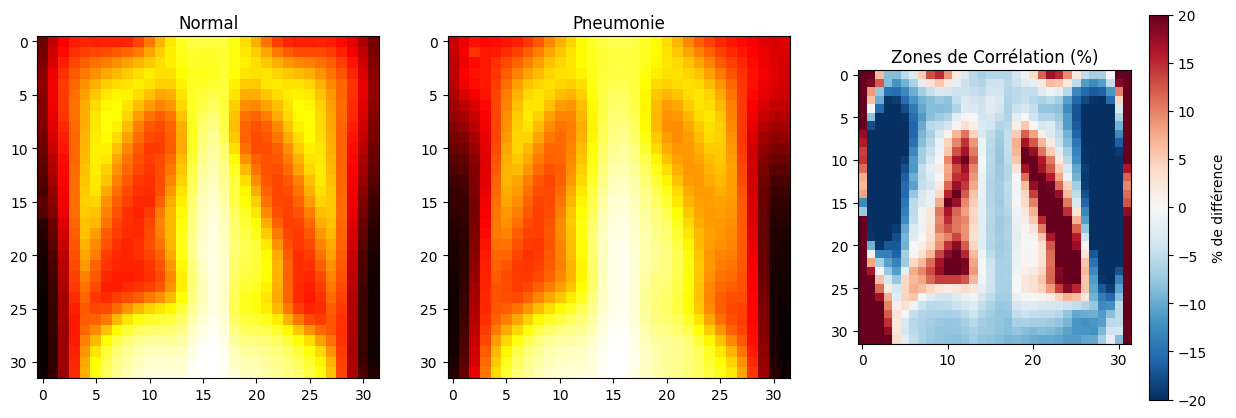

Corrélation max : +192.53% de blancheur en zone (np.int64(30), np.int64(0))


In [12]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

def main():
    path_normal_patient = os.path.abspath("../output/chest_xray/test/NORMAL")
    path_pneumonia_patient = os.path.abspath("../output/chest_xray/test/PNEUMONIA")
    
    
    print("Generating heatmaps for normal patient")
    avg_heat_normal = generate_heatmap(path_normal_patient)

    print("Generating heatmaps for pneumonia patient")
    avg_heat_pneumonia = generate_heatmap(path_pneumonia_patient)
    
    if avg_heat_normal is not None and avg_heat_pneumonia is not None:
        diff = ((avg_heat_pneumonia - avg_heat_normal) / avg_heat_normal) * 100
        plt.figure(figsize=(15, 5))

        plt.subplot(1, 3, 1)
        plt.imshow(avg_heat_normal, cmap='hot')
        plt.title("Normal")

        plt.subplot(1, 3, 2)
        plt.imshow(avg_heat_pneumonia, cmap='hot')
        plt.title("Pneumonie")

        plt.subplot(1, 3, 3)
        plt.imshow(diff, cmap='RdBu_r', vmin=-20, vmax=20)
        plt.colorbar(label='% de différence')
        plt.title("Zones de Corrélation (%)")

        plt.show()
        
        idx = np.unravel_index(np.argmax(diff), diff.shape)
        print(f"Corrélation max : +{np.max(diff):.2f}% de blancheur en zone {idx}")

if __name__ == "__main__":
    main()